# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

In [ ]:
!git clone https://github.com/cselmo/CNN-en-Skin-Dataset.git
%cd CNN-en-Skin-Dataset

Cloning into 'CNN-en-Skin-Dataset'...
remote: Enumerating objects: 872, done.
remote: Total 872 (delta 0), reused 0 (delta 0), pack-reused 872 (from 1)
Receiving objects: 100% (872/872), 167.56 MiB | 19.21 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/CNN-en-Skin-Dataset


Se agregó esta celda para clonar el repositorio en Google Colab. No se modificó ninguna constante de la sección 0 (semillas, épocas, tamaños, `SEED_SPLIT = 42`).

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [ ]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [ ]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 9s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


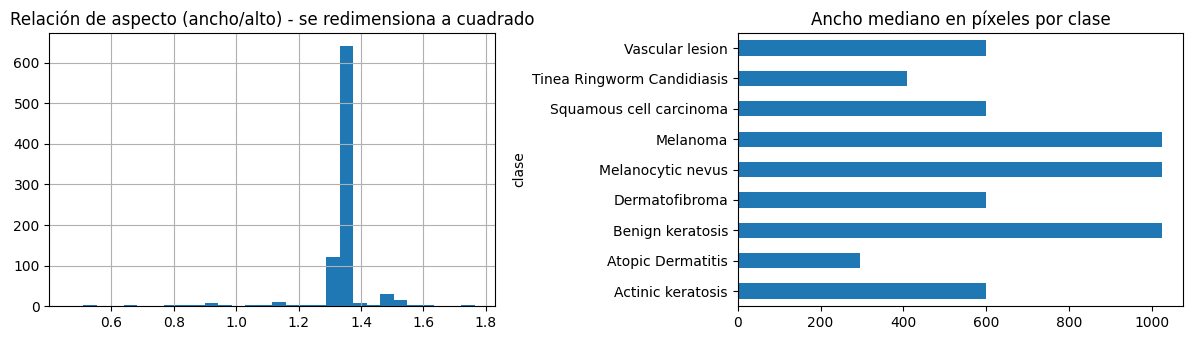

In [ ]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

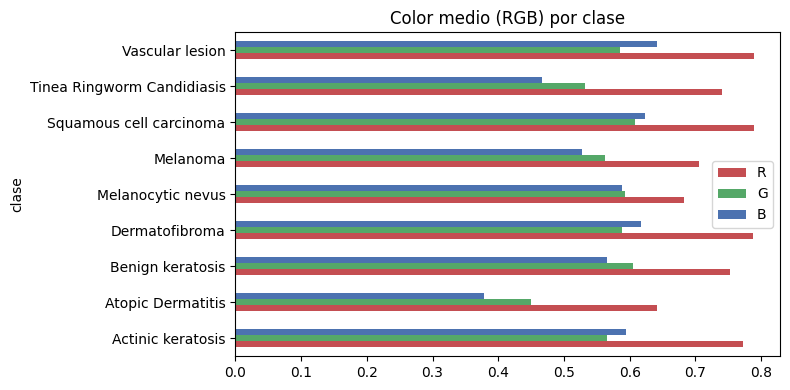

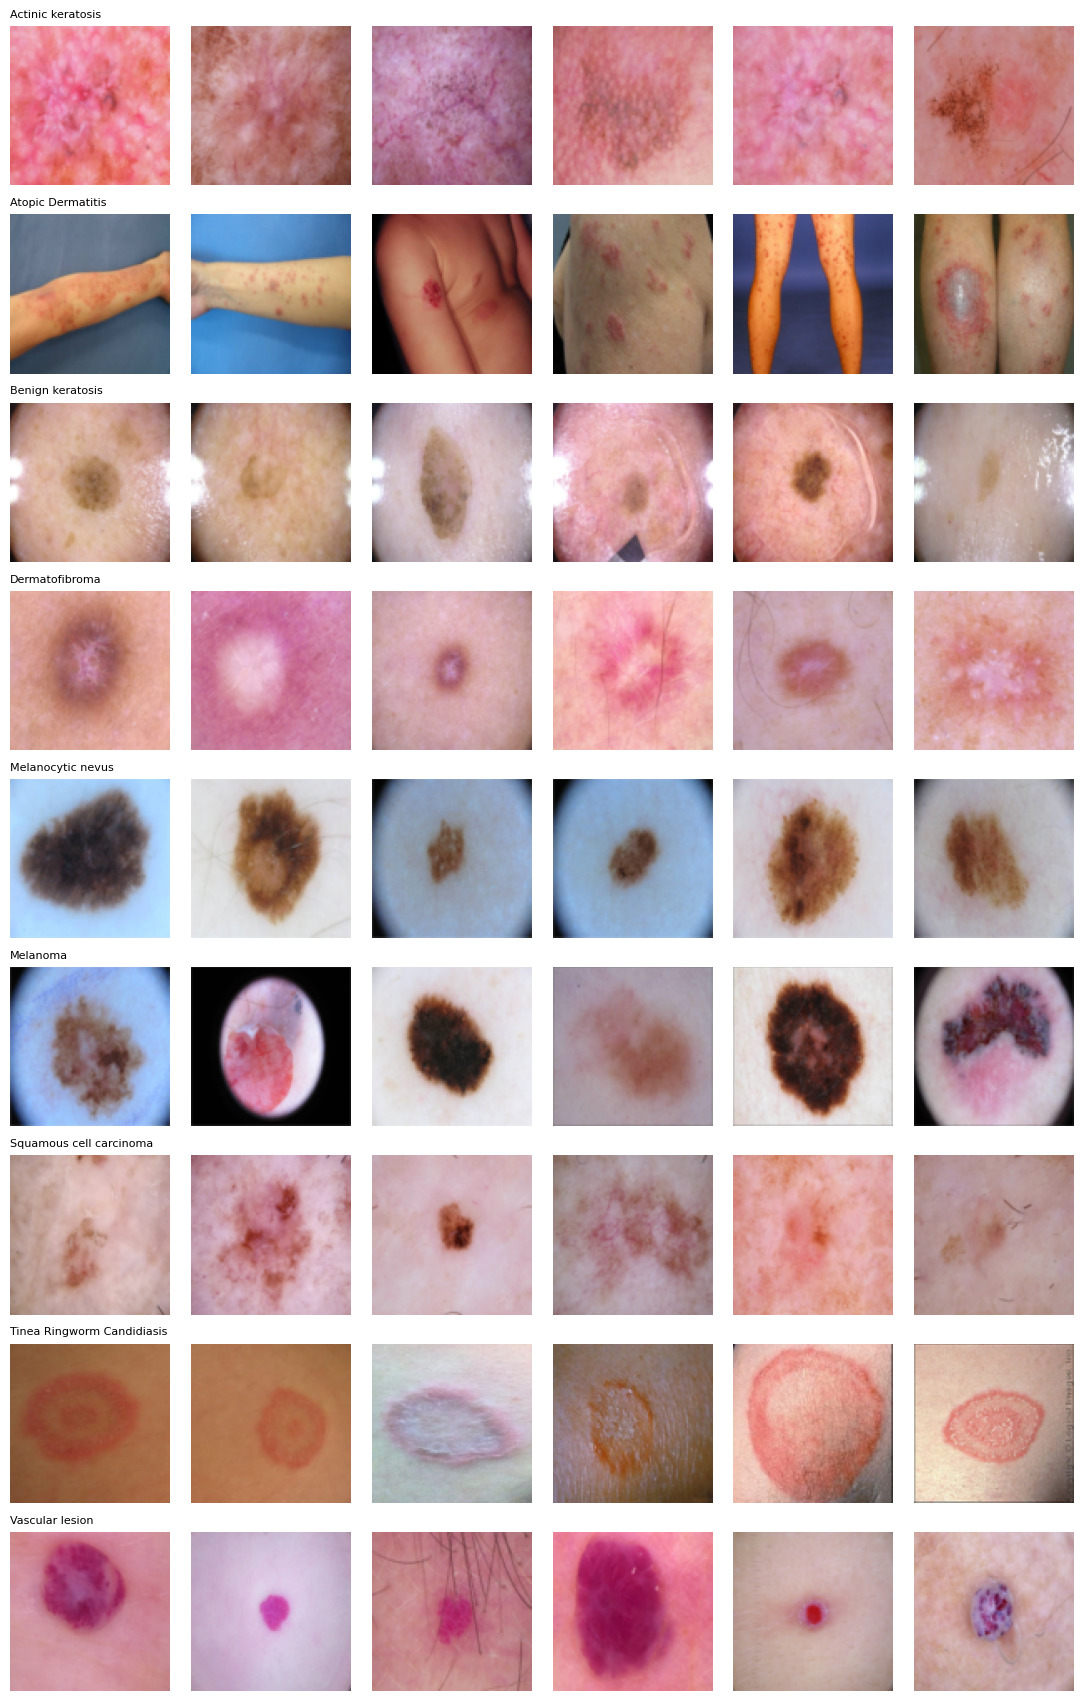

In [ ]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [ ]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
- El desbalance es leve. 7 de las clases tienen 100 imágenes, Atopic Dermatitis 102 y Tinea 76. Al eliminar duplicados, Atopic baja a 80 y Tinea a 64, porque todos los duplicados están en esas dos clases.
- En la partición original la proporción de validación no era pareja (Tinea tenía el 26% de sus imágenes en `val` y el resto el 20%).
- El nuevo split estratificado 60/20/20 (train 506, val 169, test 169) mantiene la misma proporción de cada clase en las tres partes. El azar es 1/9 ≈ 0.11.

2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
- Varias clases se reconocen por cosas que no son la lesión. Por ejemplo, Atopic Dermatitis es 100% 294×222 (la única con esa resolución), Actinic keratosis, Dermatofibroma, Squamous cell carcinoma y Vascular lesion son 100% 600×450, y Nevus, Melanoma y Benign keratosis son mayormente ~1024×768.
- Atopic y Tinea son fotos clínicas comunes (brazos, piernas, fondos azules o negros) y el resto son dermatoscópicas. Por eso, Atopic tiene el color medio más oscuro (B ≈ 0.38). Benign keratosis tiene reflejos blancos en los costados y Nevus y Melanoma suelen tener el círculo negro del dermatoscopio.
- El riesgo es que la red aprenda sobre el fondo, bordes y detalles que no tienen que ver con el lugar de la lesión. Al redimensionar, la resolución deja de verse como número, pero quedan rastros: nitidez, bordes y artefactos de compresión.

3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?
- Hay 34 grupos de imágenes idénticas (MD5), 33 repetidos entre `train` y `val`, todos en Atopic (22) y Tinea (12), sin conflictos de etiqueta.
- El hash perceptual no encontró casi-duplicados adicionales. Sin eliminarlos, el 18% de la validación original (33 de 181) serían copias de train, incluida casi toda la validación de Atopic. La red las acertaría por memoria y la `val_acc` sería más alta de lo real, sobre todo en esas dos clases.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [ ]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

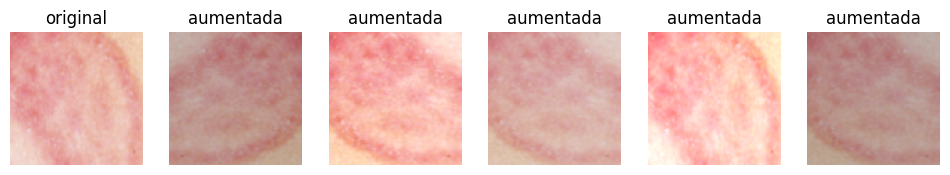

In [ ]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [ ]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [ ]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
- Con stride 1 el alto y el ancho no cambian. En la tabla, la capa 0 recibe 64×64 y sale (16, 64, 64), y la capa 4 recibe 32×32 y sale (32, 32, 32).
- Con padding=0 cada convolución perdería 2 píxeles: 64 → 62 → pool 31 → 29 → pool 14 → 12 → pool 6.
- El mapa final sería 6×6 y no 8×8, la fórmula fs dejaría de valer, la Linear esperaría 4096 entradas y recibiría 2304 (error). Además, los píxeles del borde participarían en menos cálculos.

2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
- Toma ventanas de 2×2 con paso 2 y se queda con el máximo, luego divide el alto y el ancho por 2 y no cambia los canales: 64 → 32 → 16 → 8 en las capas 3, 7 y 11. No tiene parámetros (0 en la tabla). Conserva si un patrón aparece en esa zona (la activación más fuerte), pero pierde su posición exacta, lo que da algo de tolerancia a pequeñas traslaciones. Como hay un pooling por bloque, el lado final es fs = size // 2 ** n_blocks = 64 // 8 = 8, y por eso la capa 11 sale (64, 8, 8) y el Flatten da 64·8·8 = 4096.

3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
- Segunda `Conv2d` tiene 16 canales de entrada × 32 filtros × 3 × 3 = **4608**, sin bias porque le sigue BatchNorm. Primera `Linear` de la cabeza: 4096 × 128 + 128 bias = **524416**. Ambos coinciden con la tabla. La `Linear` es el 95% de los 549273 parámetros: conecta cada una de las 4096 entradas con cada una de las 128 neuronas. Una convolución, en cambio, usa los mismos pesos en todas las posiciones de la imagen, así que su cantidad de parámetros no depende del tamaño de la imagen.

4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
- BatchNorm le resta a cada canal su media del batch, por ello cualquier constante que sume la convolución desaparece en esa resta, así que el bias no tendría efecto.

5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
- Cada pooling divide por 4 la cantidad de posiciones. Duplicar los canales compensa parte de esa pérdida y mantiene parecido el costo de cada convolución. Además, las capas profundas combinan patrones simples con patrones más complejos, y necesitan más canales para representar más tipos de patrones con menos detalle espacial.
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.
- Se empieza con r = 1 y salto j = 1. Cada conv suma (k − 1)·j y cada pooling suma 1·j y duplica j.
- Bloque 1: conv 1 + 2 = 3, pool 3 + 1 = 4, j = 2.
- Bloque 2: conv 4 + 4 = 8, pool 8 + 2 = 10, j = 4.
- Bloque 3: conv 10 + 8 = **18**.
- Cada neurona de la última conv "observa" una ventana de 18×18 píxeles, es decir, el 28% del lado de una imagen de 64 px y el 8% de su área. Ve bordes y texturas de una parte de la lesión, no la lesión entera. La vista global la da la `Linear`, que combina las 8×8 posiciones del último mapa.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 15 | val_acc 0.639 | train_acc 0.889 | 0.15 s/época | total 11s


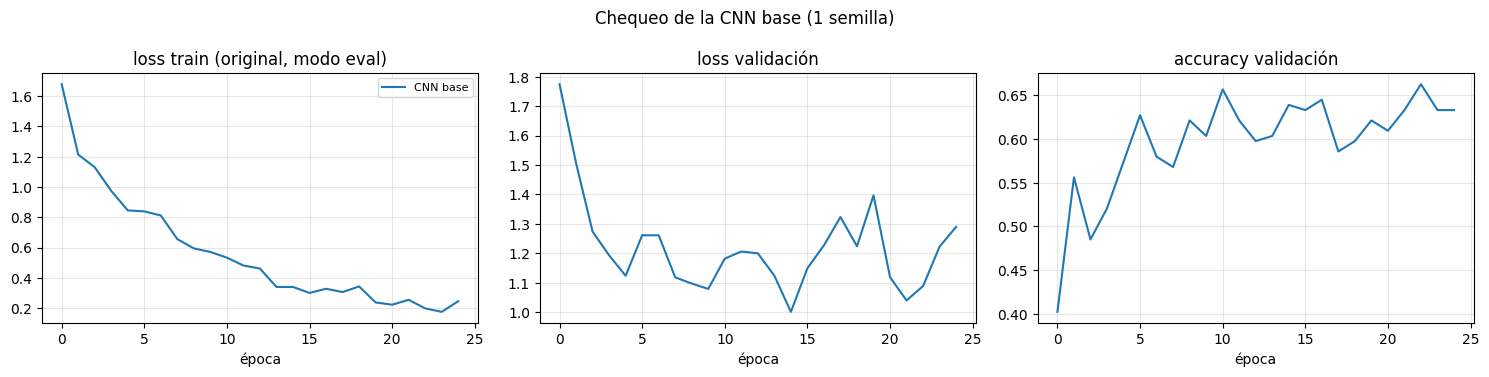

In [ ]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.0364,0.4346,0.0605
1,MLP 64px,6358793,0.5247,0.0433,0.7042,0.1796,6.6667,0.0574,0.4372,0.0874
2,CNN 32px,156057,0.6548,0.0314,0.8781,0.2233,12.3333,0.0636,0.5884,0.0664
3,CNN 64px,549273,0.6036,0.0269,0.7694,0.1659,10.6667,0.0725,0.5549,0.0487


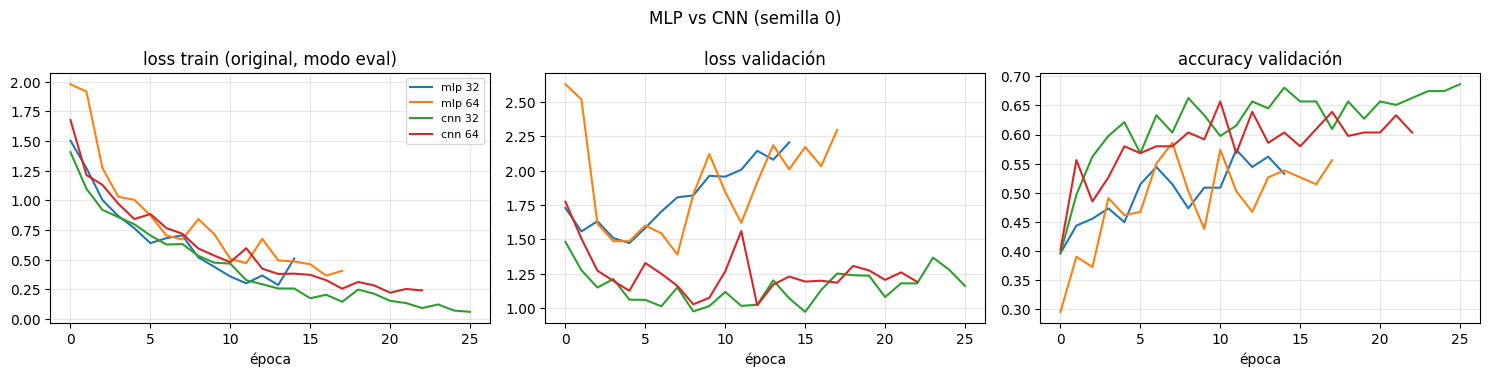

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [ ]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?


| | Parámetros | val_acc | Brecha | s/época | Mejor época |
|---|---|---|---|---|---|
| MLP 32 px | 1640201 | 0.495 ± 0.039 | 0.24 | 0.036 | 5.0 |
| MLP 64 px | 6358793 | 0.525 ± 0.043 | 0.18 | 0.057 | 6.7 |
| CNN 32 px | 156057 | 0.655 ± 0.031 | 0.22 | 0.064 | 12.3 |
| CNN 64 px | 549273 | 0.604 ± 0.027 | 0.17 | 0.073 | 10.7 |

- La CNN tiene entre 10 y 12 veces menos parámetros y es mejor: +16 puntos a 32 px y +8 a 64 px. Las dos diferencias superan el desvío entre semillas (0.03 a 0.04) y el error estándar de la validación (±0.038): la de 32 px por más de 4 errores estándar y la de 64 px por unos 2. Aunque tiene menos parámetros, la CNN tarda más por época, porque cada peso se aplica en todas las posiciones de la imagen (más operaciones por parámetro). También converge más tarde (épocas 11 a 12 contra 5 a 7): la MLP llega a su mejor validación muy rápido y después empieza a memorizar.

2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?

- La primera capa conecta cada píxel de cada canal con 512 neuronas. A 32 px: 3·32·32 = 3072 entradas → 3072 × 512 + 512 = **1573376**. A 64 px: 12288 × 512 + 512 = **6291968**. A 224 px: 150528 × 512 + 512 ≈ **77 millones**, solo en esa capa. Crece con el cuadrado del lado. La convolución lo evita por dos razones: **conectividad local** (cada neurona mira una ventana de 3×3, no toda la imagen) y **pesos compartidos** (el mismo filtro se usa en todas las posiciones). Por eso sus capas convolucionales tienen los mismos 23696 parámetros a cualquier resolución. Solo la `Linear` de la cabeza crece con la imagen.

3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
- Al desplazar la imagen 4 px (a 32) u 8 px (a 64), la MLP cae 6.1 y 8.7 puntos y la CNN 6.6 y 4.9. A 64 px la CNN se degrada menos, como predice la teoría: la convolución es equivariante (si la imagen se mueve, el mapa de activación se mueve igual) y el max pooling agrega algo de invariancia local. A 32 px no hay diferencia. La CNN tampoco es invariante del todo, porque la `Linear` de la cabeza depende de la posición en el mapa de 8×8. Las diferencias de caída (≤ 4 puntos) son del orden del ruido, así que el resultado es coherente con la teoría pero no permite concluirlo con seguridad.

4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?
- A cada canal se le resta su media y se divide por su desvío, calculados **solo con las imágenes de train** (a 64 px: media [0.743, 0.572, 0.565], desvío [0.162, 0.164, 0.186]), para que no se filtre información de validación ni de test. Así las entradas quedan centradas en 0 con escala parecida, los gradientes están mejor condicionados y el mismo `lr` sirve para todas las capas. Sin normalizar, todas las entradas serían positivas y cercanas a 0.6. Esperaría un entrenamiento más lento o inestable, sobre todo en la MLP, que no tiene BatchNorm.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6174,0.0314,0.7826,0.1653,11.0000,0.0783,1.6534
1,2 bloques,8,1055001,0.6174,0.0074,0.7852,0.1679,11.0000,0.0756,1.5712
2,4 bloques,38,361113,0.6292,0.0311,0.7826,0.1534,13.6667,0.0826,1.9504
3,kernel 5,32,591001,0.6154,0.0128,0.8116,0.1962,16.0000,0.0868,2.2275
4,kernel 7,46,653593,0.5602,0.0170,0.7437,0.1836,18.0000,0.1094,3.0597
5,8 filtros,18,269521,0.6647,0.0101,0.8999,0.2352,12.3333,0.0766,1.7028
6,32 filtros,18,1143337,0.6114,0.0155,0.7609,0.1494,10.6667,0.1132,2.3391
7,32 px,18,156057,0.6391,0.0294,0.8419,0.2028,10.6667,0.0571,1.1793
8,96 px,18,1204633,0.5680,0.0193,0.7101,0.1421,11.3333,0.1216,2.5771


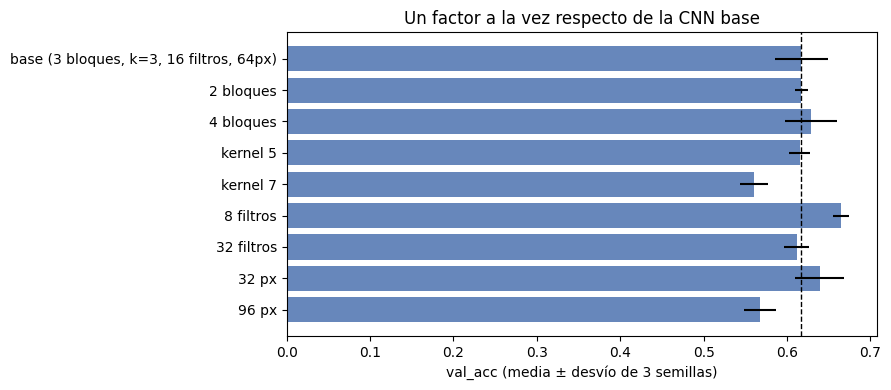

In [ ]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
- La base da 0.617 ± 0.031. Además, la misma configuración base, con las mismas semillas, dio 0.604, 0.617 y 0.631 en las tres secciones del notebook, probablemente porque algunas operaciones de la GPU no son deterministas. Es decir, el ruido real es de ~3 puntos, y el error estándar de la validación es ±0.038. Con ese criterio:
- **Diferencias más grandes, pero no concluyentes:** 8 filtros (0.665, +4.7), kernel 7 (0.560, −5.7) y 96 px (0.568, −4.9). Superan el desvío entre semillas pero no llegan a 2 errores estándar.
- **Dentro del ruido:** 2 bloques (0.617), 4 bloques (0.629), kernel 5 (0.615), 32 filtros (0.611) y 32 px (0.639).

2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
- El campo receptivo va de 8 px (2 bloques) a 18 (base), 32 (kernel 5), 38 (4 bloques) y 46 (kernel 7), es decir, del 12% al 72% del lado de una imagen de 64 px. Para bordes y texturas alcanza un campo chico, y para la asimetría global de la lesión haría falta uno grande. Esperaba mejoras al agrandarlo, pero no aparecieron. Probablemente porque la `Linear` de la cabeza ya combina todas las posiciones del último mapa y aporta la vista global. Agrandar el kernel salió caro: kernel 7 tiene 49 pesos por par de canales contra 9, es un 40% más lento por época (0.109 contra 0.078 s) y fue el peor resultado. 4 bloques tiene menos parámetros (361113) porque el mapa final es más chico (4×4), y queda dentro del ruido. Con ~60 imágenes por clase, agregar capacidad no ayuda: 8 filtros (269521 parámetros, la mitad que la base) fue lo mejor.

3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
- Las capas convolucionales tienen los mismos parámetros a cualquier resolución. La `Linear` recibe 64 · (size/8)² entradas: 1024 a 32 px, 4096 a 64 y 9216 a 96. Sus parámetros pasan de 131200 a 524416 y a 1179776: crecen con el cuadrado del lado. A más resolución hay más detalle de textura y bordes, pero el tiempo por época sube (0.057 → 0.078 → 0.122 s) y el campo receptivo de 18 px cubre una parte cada vez menor de la imagen (56% → 28% → 19%). Con tan pocas imágenes, la cabeza más grande sobreajusta más fácil, y a 96 px el resultado empeoró. El experimento mezcla tres efectos (más detalle, más parámetros en la cabeza y menor campo receptivo relativo), así que no se puede atribuir la caída a uno solo.
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?
- "Un factor a la vez" no muestra interacciones: por ejemplo, 96 px podría funcionar con más bloques, o 8 filtros con otro `lr`. El `lr` (3e-3) es el mismo para todas las variantes, sin ajustar. Con 3 semillas el desvío también es impreciso, hay una sola partición y la validación es chica. Por último, elegir la mejor de 9 variantes por validación es optimista: la ganadora probablemente tuvo algo de suerte.

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6312,0.0339,0.7925,0.1613,0.9927,11.3333,0.0734,1.5733
1,flips,1518,0.6134,0.0074,0.8406,0.2272,1.0370,10.0000,0.2185,4.3822
2,flips+rot90,1518,0.6331,0.0476,0.8254,0.1923,1.1149,12.3333,0.2151,4.8038
3,flips+rot90+color,1518,0.6588,0.0101,0.8050,0.1462,0.9607,10.0000,0.2215,4.4189


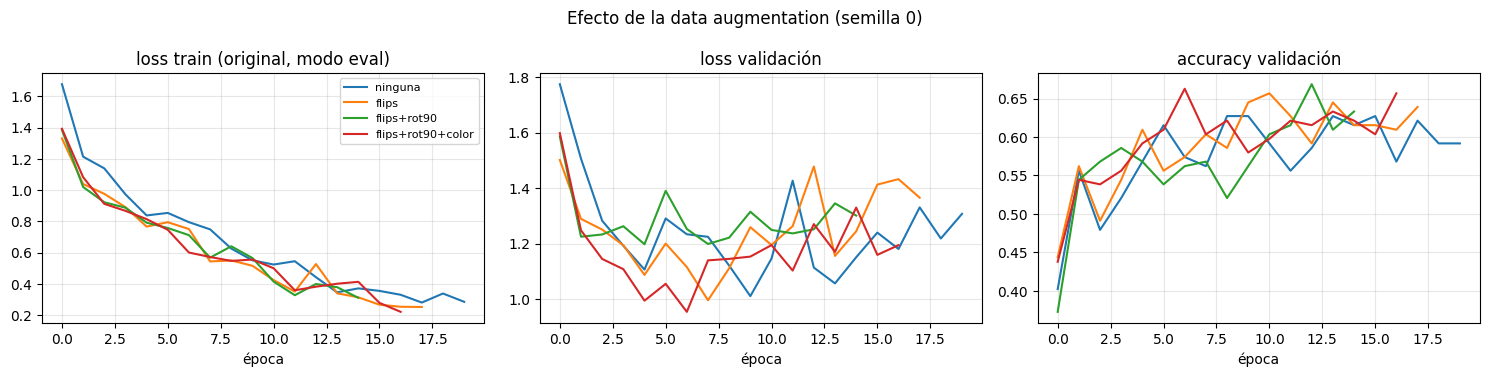

In [ ]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
- En la CNN base, la accuracy de train en la mejor época es 0.79 y la de validación 0.63: una brecha de 0.16. En las curvas de la semilla 0, la `val_loss` llega a su mínimo (aprox 1.0) cerca de la época 10 y después sube con oscilaciones (aprox 1.4 en la época 12), mientras la loss de train sigue bajando hasta ~0.28. En el chequeo de la sección 4.2 pasa lo mismo: mínimo de `val_loss` en la época 15 y después sube hasta ~1.4, con la loss de train cayendo a ~0.2. El early stopping guarda el modelo de la mejor época, así que la brecha reportada subestima cuánto sobreajustaría si siguiera entrenando.

2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
- Solo la augmentation completa bajó la brecha (0.15) y la `val_loss` (0.96) y subió la `val_acc` (+2.8 puntos). Los flips solos aumentaron la brecha: con 3 veces más pasadas por época, la red ajusta mejor las imágenes originales de train. La época de convergencia casi no cambia. Cada época cuesta ~3 veces más porque el set de train pasa de 506 a 1518 imágenes (las originales más 2 copias aumentadas de cada una). **Ninguna mejora supera el ruido:** +2.8 puntos es menos que el error estándar (±0.038) y que la variación de la base entre corridas. Además, las copias se generan una sola vez antes de entrenar (con semilla fija), así que la red ve siempre las mismas 2 versiones de cada imagen. Generarlas de nuevo en cada época daría más variedad.

3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
- Flips y rotaciones de 90° tienen sentido: una lesión vista con dermatoscopio no tiene "arriba" ni "abajo", y su diagnóstico no cambia si se rota. El color es delicado: es información diagnóstica (los varios colores y el velo azul-blanco del melanoma, el rojo-violeta de las lesiones vasculares). Un cambio moderado de brillo y contraste (±20%, como acá) simula distintas cámaras e iluminación, y además puede reducir la dependencia de los atajos de color vistos en el EDA. Cambiar el tono sí destruiría información. La escala también: el diámetro es un criterio clínico (ABCDE), aunque sin regla en la foto su valor absoluto no se conoce. Probaría rotaciones de cualquier ángulo, recortes y zoom moderados, pequeñas traslaciones, desenfoque o ruido leve, y simulación de pelos. También normalizaría el color entre dispositivos.

4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
- Si se aumentara antes de dividir, copias de una misma imagen terminarían en train y en validación o test. Sería la misma fuga que los duplicados del EDA: la red acertaría por memoria y las métricas saldrían infladas. Validación y test tienen que representar imágenes nuevas tal como llegarían en la práctica. Aumentarlos agregaría copias correlacionadas que no aportan información nueva y harían parecer más chico el error estándar de lo que realmente es.

5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?
- Dropout y L2 regularizan restringiendo el modelo (apagan neuronas o limitan los pesos) sin agregar información. La augmentation agrega conocimiento del problema: le dice a la red que la clase no cambia si la imagen se rota o se ilumina distinto. No limita la capacidad, pero cuesta más cómputo (~3 veces el tiempo por época, contra +3% del dropout en el TP3). En el TP3, dropout mejoró 2.6 puntos con un efecto mayor que el ruido, gracias a 2263 imágenes de validación. Acá la mejora es parecida (+2.8), pero con 169 imágenes de validación el error estándar es unas 4 veces mayor y no alcanza para afirmarlo.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [ ]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 8 filtros | mejor augmentation (val): flips+rot90+color
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 3, 'filters': 8, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90+color'}
Config final en validación: val_acc 0.653 ± 0.017 | brecha 0.170 | mejor época 9.3 | 4s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,269521,0.6462,0.0369,0.6484,0.0377,3.9682
1,MLP 64px,6358793,0.5041,0.0534,0.4872,0.0572,0.9448


Error estándar binomial del test (169 imágenes): ±0.037 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.35      0.35      0.35        20
         Atopic Dermatitis       0.82      0.88      0.85        16
          Benign keratosis       0.95      0.90      0.92        20
            Dermatofibroma       0.42      0.50      0.45        20
         Melanocytic nevus       0.68      0.75      0.71        20
                  Melanoma       0.50      0.35      0.41        20
   Squamous cell carcinoma       0.33      0.40      0.36        20
Tinea Ringworm Candidiasis       0.67      0.62      0.64        13
           Vascular lesion       1.00      0.85      0.92        20

                  accuracy                           0.62       169
                 macro avg       0.64      0.62      0.62       169
              weighted avg       0.63      0.62      0.62       169



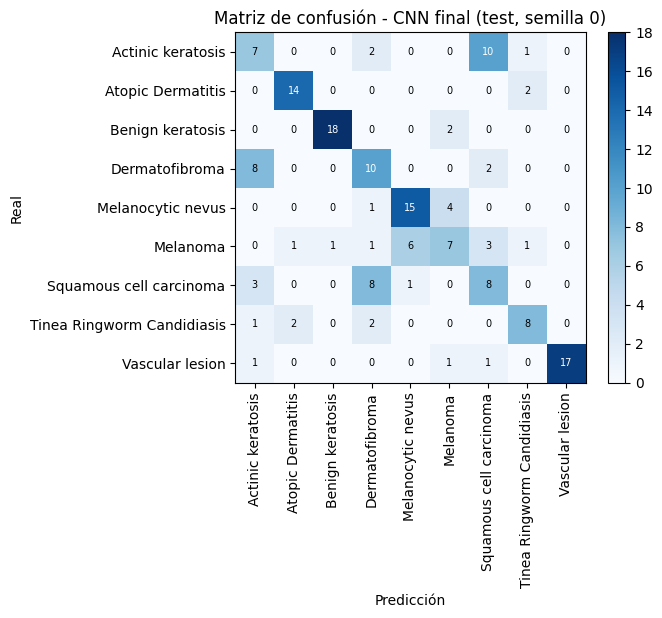

In [ ]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

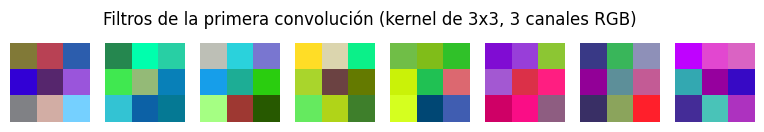

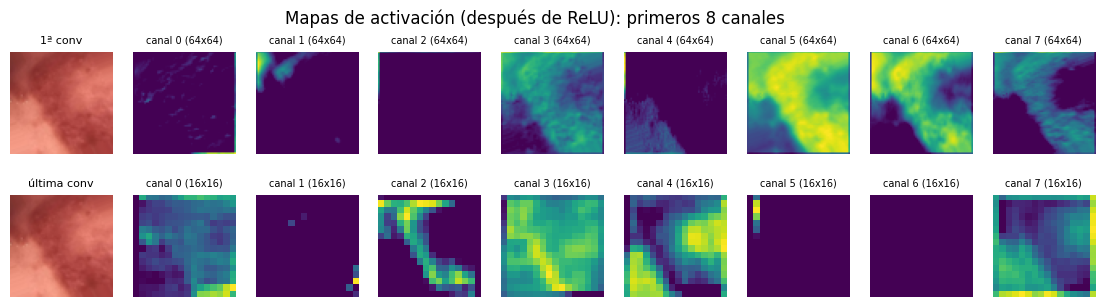

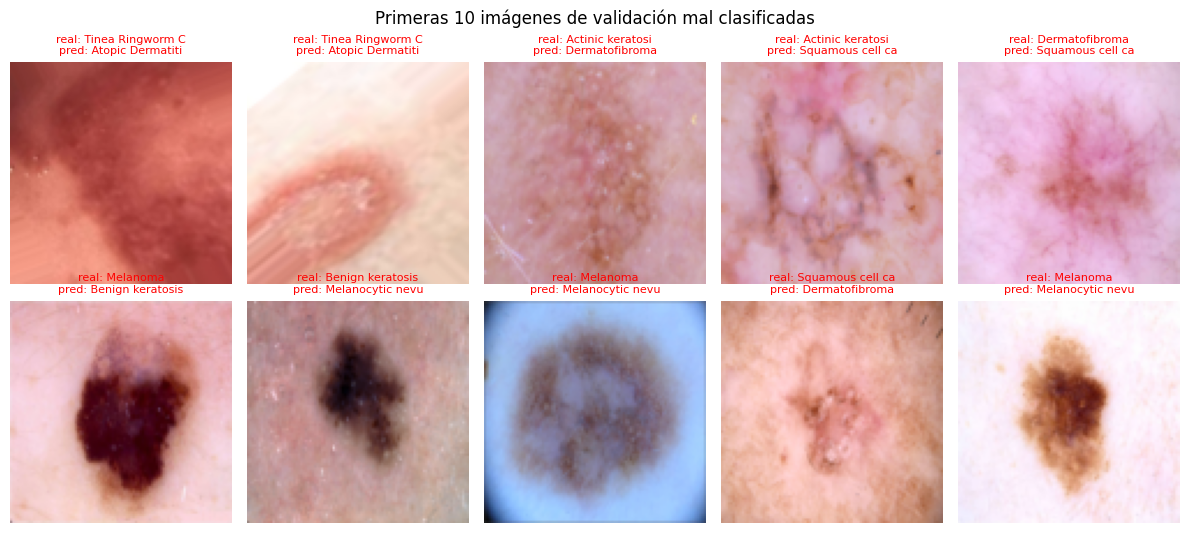

In [ ]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación

Configuración final, elegida en validación: CNN de 3 bloques con **8 filtros**, 64 px, augmentation **flips + rot90 + color**, 269521 parámetros.

1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
- En validación dio 0.653 ± 0.017 (3 semillas) y en test **0.646 ± 0.037** (5 semillas), una diferencia de 0.7 puntos, mucho menor que el error estándar del test (±0.037): son coherentes. Era esperable algo de optimismo, porque elegimos la mejor de 9 arquitecturas y 4 augmentations en validación. Se nota una caída gradual: 8 filtros sola dio 0.665, combinada con augmentation 0.653 y en test 0.646. Pero es pequeña.

2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
- CNN 0.646 ± 0.037 (F1 macro 0.648) contra MLP 0.504 ± 0.053 (F1 0.487). La diferencia de 14 puntos supera el desvío de ambas y equivale a casi 4 errores estándar: es real. La CNN tiene 24 veces menos parámetros (269521 contra 6358793). Tarda 4 veces más en entrenar (4.0 contra 0.9 s), sobre todo porque entrena con 3 veces más imágenes por la augmentation. En segundos, el costo es despreciable frente a la ganancia.

3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
- Las mejores clases son Benign keratosis (F1 0.92), Vascular lesion (0.92) y Atopic Dermatitis (0.85). Las peores son Actinic keratosis (0.35), Squamous cell carcinoma (0.36), Melanoma (0.41) y Dermatofibroma (0.45). Las confusiones tienen sentido clínico. Por un lado, Actinic keratosis se confunde con carcinoma escamoso (10 de 20), dado que la queratosis actínica es una lesión precursora de ese carcinoma y ambas son rosadas y escamosas. Por otro lado, Dermatofibroma y carcinoma escamoso se cruzan con Actinic keratosis (8 cada uno). Por su parte, Melanoma se confunde con nevo (6 de 20), la distinción clásicamente más difícil. Cabe destacar que no todos los errores tienen la misma gravedad. Clasificar un melanoma como nevo benigno retrasa el diagnóstico de un cáncer, mientras que lo inverso solo genera una consulta extra. Acá el recall de melanoma es de 0.35 porque solo detecta 7 de 20. La accuracy oculta esto. Las métricas más relevantes son el **recall de las clases malignas** (melanoma y carcinoma) y el F1 macro, que pesa igual a todas las clases.

4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
- Los filtros de la primera conv (3×3) son combinaciones de colores: detectan zonas de cierto color y cambios de color, más que formas. Sus mapas (64×64) separan la piel clara de la lesión y marcan los bordes de la imagen. Los mapas de la última conv (16×16) son más gruesos y abstractos: algunos canales siguen el borde entre la lesión y la piel y otros quedan apagados. Varios canales se activan en los bordes de la imagen, lo que podría indicar que la red usa los bordes, un posible atajo. Los errores de validación muestran patrones claros: lesiones rosadas y texturadas sin borde definido (Actinic keratosis, Dermatofibroma y carcinoma, que se confunden entre sí), lesiones pigmentadas oscuras (melanoma tomado como nevo o queratosis benigna) y fotos clínicas de Tinea tomadas como Atopic Dermatitis, las dos clases de fotos no dermatoscópicas.

5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?
- Algunas clases vienen de fuentes distintas (resolución, fondo, foto clínica o dermatoscópica, reflejos, círculo del dermatoscopio). Eso puede inflar los resultados de Atopic, Tinea y Benign keratosis, que justamente son de las mejor clasificadas. Se eliminaron los duplicados exactos, pero podría haber fotos distintas de la misma lesión o del mismo paciente repartidas entre train y test, y eso no se puede verificar sin metadatos. Las imágenes son casi todas de piel clara, así que no se sabe cómo funcionaría con otros tonos de piel. El dataset es chico (844 imágenes, 38 a 60 por clase en train), hay una sola partición, 3 semillas, y la validación y el test tienen 169 imágenes (±0.037). Además, la GPU no es determinista: la misma configuración dio 0.604, 0.617 y 0.631. Con más tiempo, usaría validación cruzada o varias particiones, más semillas y modo determinista, augmentation nueva en cada época y una red preentrenada (transfer learning). También mediría el recall de melanoma, revisaría con mapas de atención si la red mira la lesión o el fondo, y recortaría el círculo del dermatoscopio.

## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

Sí. Usé Claude para entender los conceptos del TP (convolución, pooling, campo receptivo, augmentation), interpretar los outputs y redactar borradores de las celdas de análisis a partir de los resultados de las ejecuciones. Verifiqué las cuentas de parámetros y del campo receptivo con la tabla del notebook, revisé que cada número coincida con las salidas y adapté los textos.